# Pandas - Topic 08 - Data Manipulation Part 1


## Topic Objectives

- Rename DataFrame columns
- Select columns based on their data type
- Convert Pandas DataFrames to NumPy arrays


## Import Package for Learning

In [41]:
import numpy as np
import pandas as pd

## Pandas - Topic 08 - Data Manipulation Part 1

In this notebook, we will cover

- how to rename your DataFrame columns with .columns and .rename()
- how to select data based on their type with .select_dtypes()
- how to convert Pandas DataFrames to NumPy array with .values

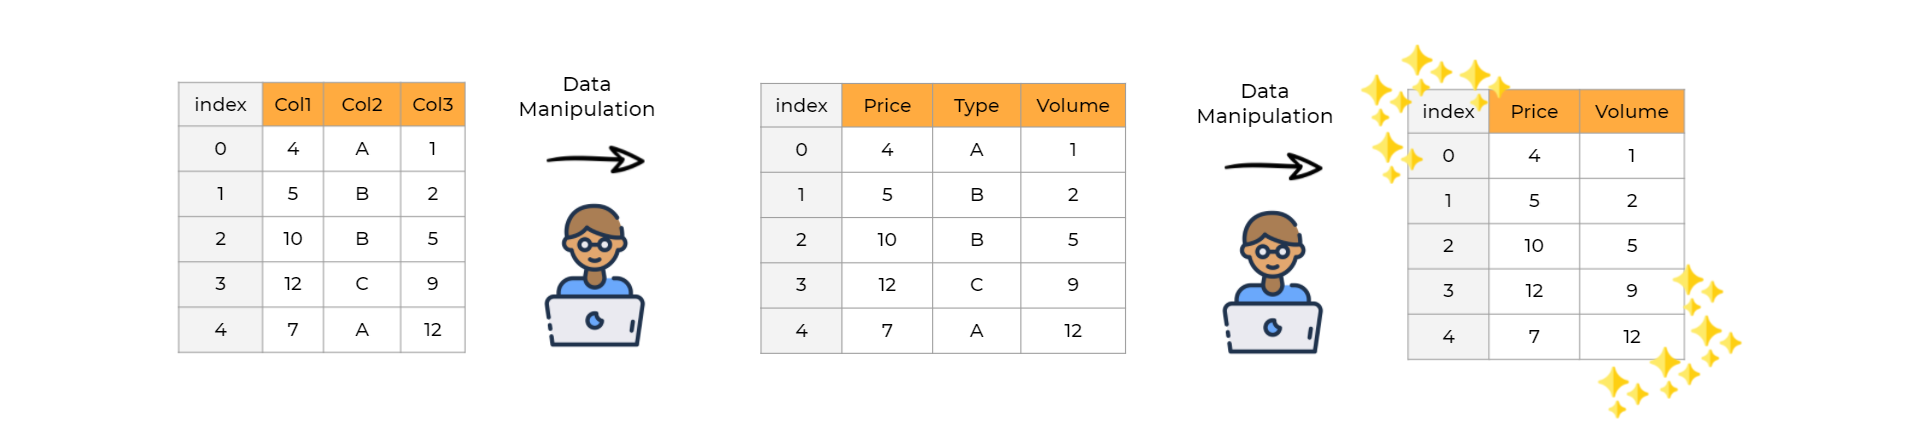

Consider the dataset from the previous unit

In [42]:
df = pd.DataFrame(data={'Col1':np.random.randint(low=0,high=50,size=10),
                        'Col2':np.random.randn(10),
                        'Col3':['A','B','C','A','A','C','D','B','A','A'],
                        'Col4':np.random.choice([True, False],size=10),
                        'Col5':np.random.randint(low=1,high=4,size=10)},
                  index=pd.date_range(start='01/01/2021', periods=10, freq='M'))
df

C:\Users\zainab\AppData\Local\Temp\ipykernel_13588\2898990506.py:6: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  index=pd.date_range(start='01/01/2021', periods=10, freq='M'))


,Col1,Col2,Col3,Col4,Col5
2021-01-31,41,0.904780,A,False,1
2021-02-28,11,-0.409922,B,False,3
2021-03-31,8,0.043885,C,False,2
2021-04-30,47,0.057502,A,True,2
2021-05-31,41,1.558564,A,False,3
2021-06-30,33,0.594563,C,False,1
2021-07-31,16,-0.052208,D,True,2
2021-08-31,23,-0.247473,B,False,3
2021-09-30,44,0.095708,A,False,1
2021-10-31,31,-0.482394,A,True,2


## Rename Columns

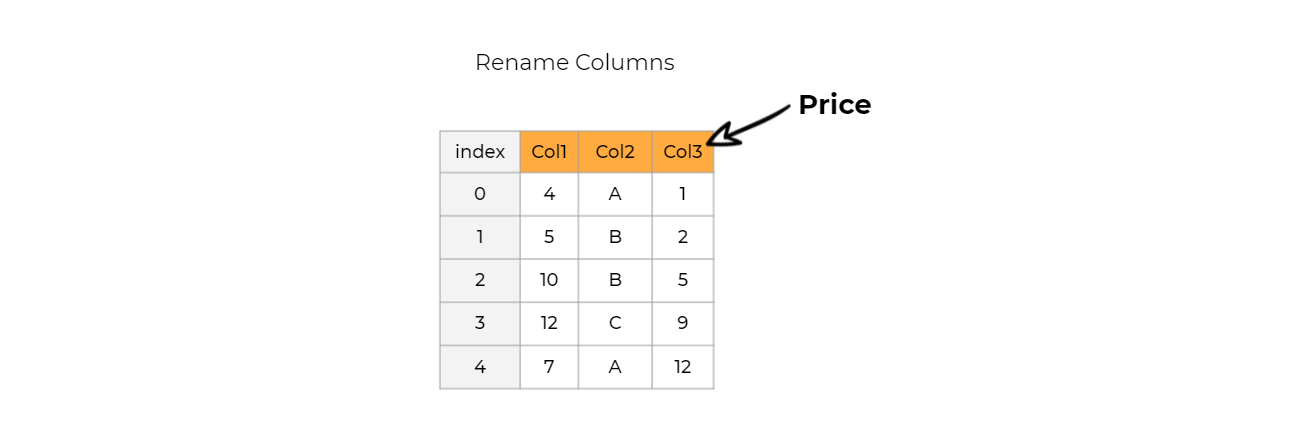

You can rename your columns using two approaches

- assigning to df.columns a list with the column names you want
- or using .rename()

First we create a separate DataFrame for this example

In [43]:
df_example = df.copy()
df_example.head()

,Col1,Col2,Col3,Col4,Col5
2021-01-31,41,0.904780,A,False,1
2021-02-28,11,-0.409922,B,False,3
2021-03-31,8,0.043885,C,False,2
2021-04-30,47,0.057502,A,True,2
2021-05-31,41,1.558564,A,False,3


Then we assign to df.columns a list with the column names we want

In [44]:
df_example.columns = ['Revenue', 'Rate', 'ProfileCategory', 'Flag', 'ClassCategory']
df_example.head()

,Revenue,Rate,ProfileCategory,Flag,ClassCategory
2021-01-31,41,0.904780,A,False,1
2021-02-28,11,-0.409922,B,False,3
2021-03-31,8,0.043885,C,False,2
2021-04-30,47,0.057502,A,True,2
2021-05-31,41,1.558564,A,False,3


Alternatively you can use .rename(). The documentation is here. You should parse a list mapping the old column names and new column names using the 'columns' argument. Note we set inplace=True, to overwrite the DataFrame

- This is useful and can save time when you have a long list of columns and don't want to list all the column names. You just map to rename the columns in which you are interested in changing. In this example, we just mapped three columns. The others remain the same.

In [45]:
df_example = df.copy()
df_example = df_example.rename(columns={"Col1":"Revenue",
                                        "Col2":"Rate",
                                        'Col4':'Flag'})
df_example.head()

,Revenue,Rate,Col3,Flag,Col5
2021-01-31,41,0.904780,A,False,1
2021-02-28,11,-0.409922,B,False,3
2021-03-31,8,0.043885,C,False,2
2021-04-30,47,0.057502,A,True,2
2021-05-31,41,1.558564,A,False,3


We can use the argument inplace=True as an alternative. This creates a new DataFrame. The difference is that you don't have to reassign the variable.

In [46]:
df_example = df.copy()
df_example.rename(columns={"Col1":"Revenue",
                           "Col2":"Rate",
                           'Col4':'Flag'},inplace=True)
df_example.head()

,Revenue,Rate,Col3,Flag,Col5
2021-01-31,41,0.904780,A,False,1
2021-02-28,11,-0.409922,B,False,3
2021-03-31,8,0.043885,C,False,2
2021-04-30,47,0.057502,A,True,2
2021-05-31,41,1.558564,A,False,3


## Selecting data based on data types¶

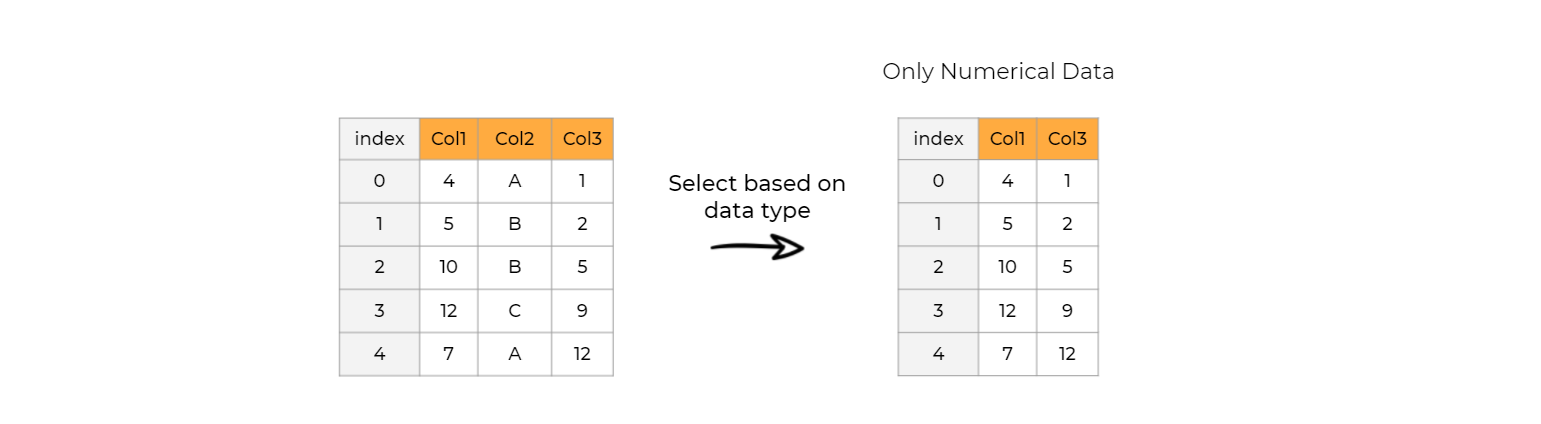

Let's recap df first

In [47]:
df

,Col1,Col2,Col3,Col4,Col5
2021-01-31,41,0.904780,A,False,1
2021-02-28,11,-0.409922,B,False,3
2021-03-31,8,0.043885,C,False,2
2021-04-30,47,0.057502,A,True,2
2021-05-31,41,1.558564,A,False,3
2021-06-30,33,0.594563,C,False,1
2021-07-31,16,-0.052208,D,True,2
2021-08-31,23,-0.247473,B,False,3
2021-09-30,44,0.095708,A,False,1
2021-10-31,31,-0.482394,A,True,2


You can select data based on data type with .select_dtypes(). This function documentation is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.select_dtypes.html)

- Say you are interested to subset only numerical data, you should set the "include" argument as 'number'
- You might do this if you want to create a scatterplot

In [48]:
df.select_dtypes(include='number')

,Col1,Col2,Col5
2021-01-31,41,0.904780,1
2021-02-28,11,-0.409922,3
2021-03-31,8,0.043885,2
2021-04-30,47,0.057502,2
2021-05-31,41,1.558564,3
2021-06-30,33,0.594563,1
2021-07-31,16,-0.052208,2
2021-08-31,23,-0.247473,3
2021-09-30,44,0.095708,1
2021-10-31,31,-0.482394,2


Now you are interested to subset only categorical data; you should set the "include" argument as 'object'

In [49]:
df.select_dtypes(include='object')

,Col3
2021-01-31,A
2021-02-28,B
2021-03-31,C
2021-04-30,A
2021-05-31,A
2021-06-30,C
2021-07-31,D
2021-08-31,B
2021-09-30,A
2021-10-31,A


If you want boolean data, set the 'include' argument as 'boolean'

In [50]:
df.select_dtypes(include='bool')

,Col4
2021-01-31,False
2021-02-28,False
2021-03-31,False
2021-04-30,True
2021-05-31,False
2021-06-30,False
2021-07-31,True
2021-08-31,False
2021-09-30,False
2021-10-31,True


If you want a combination of multiple data types, parse them in a list.

- The example below considers boolean and number types

In [51]:
df.select_dtypes(include=['boolean','number'])

,Col1,Col2,Col4,Col5
2021-01-31,41,0.904780,False,1
2021-02-28,11,-0.409922,False,3
2021-03-31,8,0.043885,False,2
2021-04-30,47,0.057502,True,2
2021-05-31,41,1.558564,False,3
2021-06-30,33,0.594563,False,1
2021-07-31,16,-0.052208,True,2
2021-08-31,23,-0.247473,False,3
2021-09-30,44,0.095708,False,1
2021-10-31,31,-0.482394,True,2


For the next example, we create a separate DataFrame df1, and reset the index of df.

- The previous index became a column called 'index'

In [52]:
df1 = df.reset_index()
df1

,index,Col1,Col2,Col3,Col4,Col5
0,2021-01-31,41,0.904780,A,False,1
1,2021-02-28,11,-0.409922,B,False,3
2,2021-03-31,8,0.043885,C,False,2
3,2021-04-30,47,0.057502,A,True,2
4,2021-05-31,41,1.558564,A,False,3
5,2021-06-30,33,0.594563,C,False,1
6,2021-07-31,16,-0.052208,D,True,2
7,2021-08-31,23,-0.247473,B,False,3
8,2021-09-30,44,0.095708,A,False,1
9,2021-10-31,31,-0.482394,A,True,2


We now want to select from df1, the columns where the datatype is equal to '`datetime`'

In [53]:
df1.select_dtypes(include='datetime')

,index
0,2021-01-31
1,2021-02-28
2,2021-03-31
3,2021-04-30
4,2021-05-31
5,2021-06-30
6,2021-07-31
7,2021-08-31
8,2021-09-30
9,2021-10-31


You can also reverse logic, and use the exclude parameter when you don't want a specific data type in your DataFrame.

- Naturally, you can use it for all the data types we showed earlier
- We will showcase using 'number' only

In [54]:
df.select_dtypes(exclude='number')

,Col3,Col4
2021-01-31,A,False
2021-02-28,B,False
2021-03-31,C,False
2021-04-30,A,True
2021-05-31,A,False
2021-06-30,C,False
2021-07-31,D,True
2021-08-31,B,False
2021-09-30,A,False
2021-10-31,A,True


## Convert a Pandas DataFrame to a NumPy array

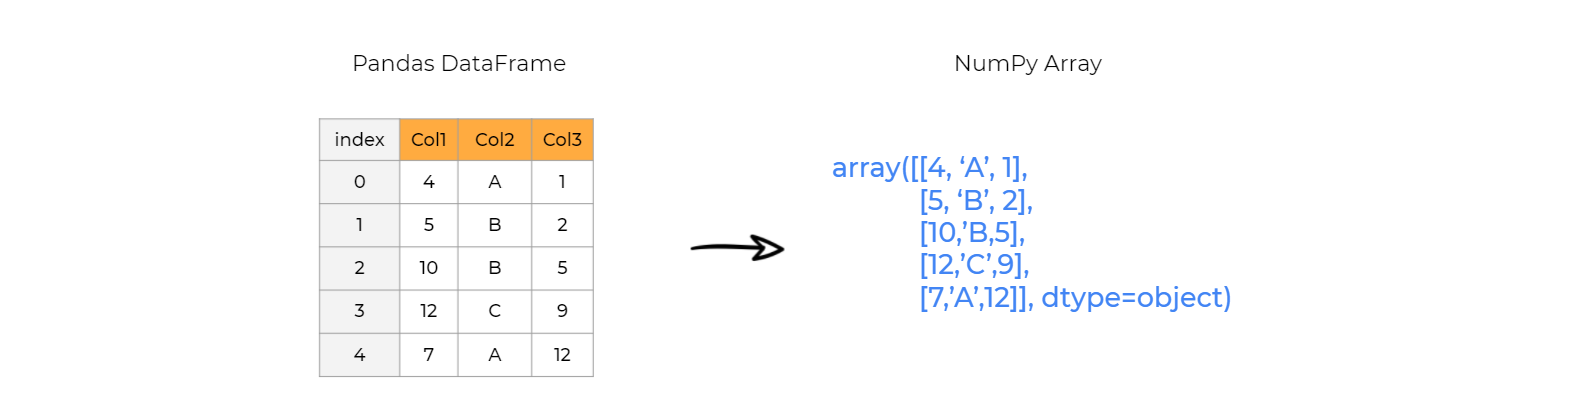

You can convert a Pandas DataFrame to a NumPy Array with .to_numpy()

- This operation is needed for future lessons when training machine learning models since some of them need the data as an array
- Just a quick recap on df

In [55]:
df

,Col1,Col2,Col3,Col4,Col5
2021-01-31,41,0.904780,A,False,1
2021-02-28,11,-0.409922,B,False,3
2021-03-31,8,0.043885,C,False,2
2021-04-30,47,0.057502,A,True,2
2021-05-31,41,1.558564,A,False,3
2021-06-30,33,0.594563,C,False,1
2021-07-31,16,-0.052208,D,True,2
2021-08-31,23,-0.247473,B,False,3
2021-09-30,44,0.095708,A,False,1
2021-10-31,31,-0.482394,A,True,2


Now converting to an array. Note the index is not included

In [56]:
df.to_numpy()

array([[41, 0.9047803825009425, 'A', False, 1],
       [11, -0.4099224222559365, 'B', False, 3],
       [8, 0.043885187953963886, 'C', False, 2],
       [47, 0.05750171896667674, 'A', True, 2],
       [41, 1.5585639783548348, 'A', False, 3],
       [33, 0.5945627904841311, 'C', False, 1],
       [16, -0.05220826669444925, 'D', True, 2],
       [23, -0.24747277852475147, 'B', False, 3],
       [44, 0.09570788546685616, 'A', False, 1],
       [31, -0.4823935090121206, 'A', True, 2]], dtype=object)

Alternatively, you can convert it to a NumPy array using the attribute .values

In [57]:
df.values

array([[41, 0.9047803825009425, 'A', False, 1],
       [11, -0.4099224222559365, 'B', False, 3],
       [8, 0.043885187953963886, 'C', False, 2],
       [47, 0.05750171896667674, 'A', True, 2],
       [41, 1.5585639783548348, 'A', False, 3],
       [33, 0.5945627904841311, 'C', False, 1],
       [16, -0.05220826669444925, 'D', True, 2],
       [23, -0.24747277852475147, 'B', False, 3],
       [44, 0.09570788546685616, 'A', False, 1],
       [31, -0.4823935090121206, 'A', True, 2]], dtype=object)